Dataset loaded successfully
Total samples: 1404

Performance Metrics per Prompting Strategy:
        pipeline  accuracy  precision  recall  f1_score
0  KAG_zero_shot    0.3000     0.3061  0.3000    0.2069
1   KAG_few_shot    0.4792     0.6744  0.4792    0.5241
2        KAG_cot    0.5875     0.6512  0.5875    0.5915
3  RAG_zero_shot    0.4254     0.3731  0.4254    0.3325
4   RAG_few_shot    0.4342     0.5858  0.4342    0.4647
5        RAG_cot    0.4912     0.6083  0.4912    0.4920


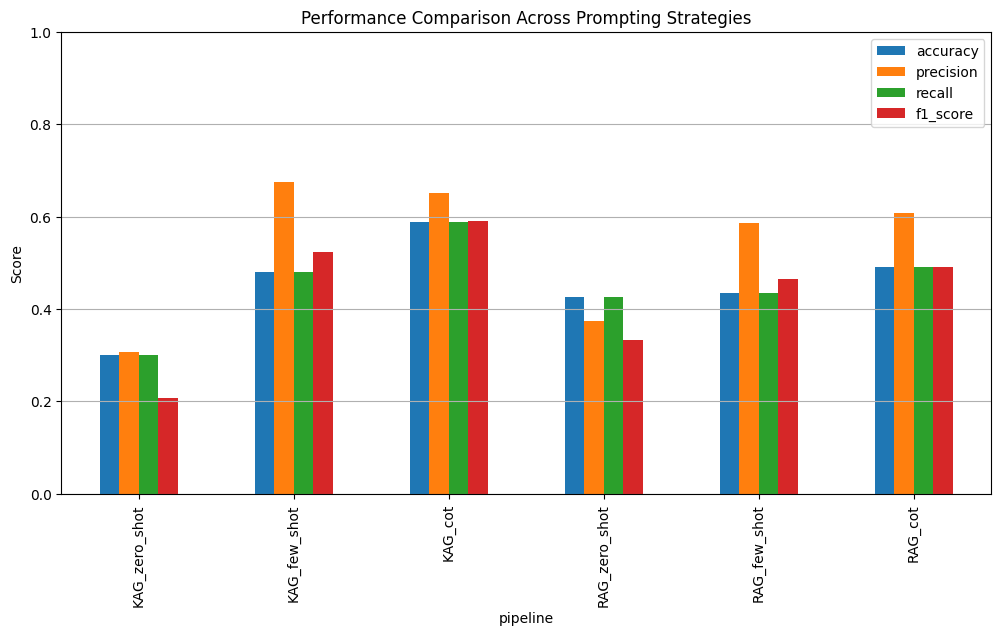


Correlation Matrix:
                 confidence  input_tokens  latency_s  energy_kwh  carbon_kg  \
confidence              NaN           NaN        NaN         NaN        NaN   
input_tokens            NaN         1.000     -0.302      -0.228     -0.228   
latency_s               NaN        -0.302      1.000       0.992      0.992   
energy_kwh              NaN        -0.228      0.992       1.000      1.000   
carbon_kg               NaN        -0.228      0.992       1.000      1.000   
avg_power_watts         NaN         0.645     -0.353      -0.237     -0.237   

                 avg_power_watts  
confidence                   NaN  
input_tokens               0.645  
latency_s                 -0.353  
energy_kwh                -0.237  
carbon_kg                 -0.237  
avg_power_watts            1.000  


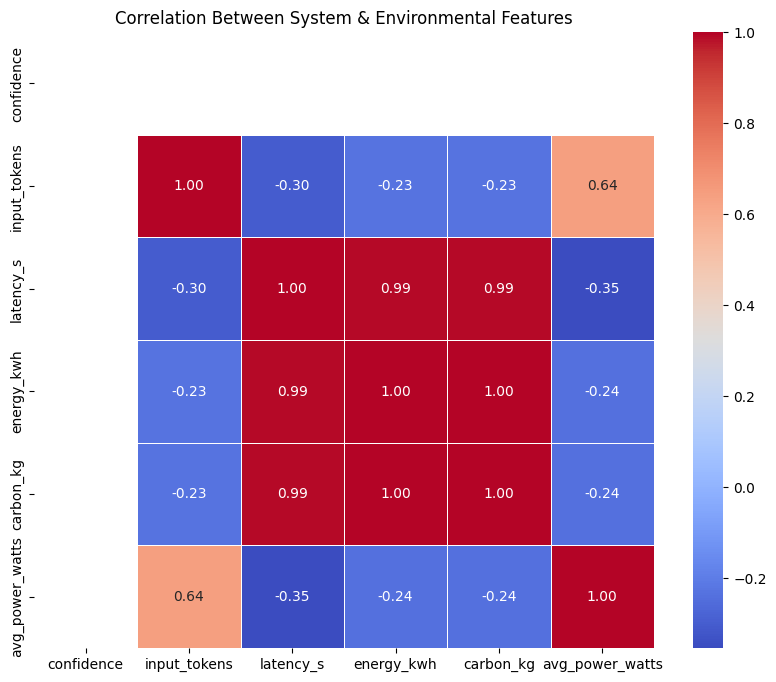


Correlation with Model Confidence:
confidence        NaN
input_tokens      NaN
latency_s         NaN
energy_kwh        NaN
carbon_kg         NaN
avg_power_watts   NaN
Name: confidence, dtype: float64

Mean Resource Usage per Prompting Strategy:
        pipeline  mean_tokens  mean_latency  mean_energy  mean_carbon  \
0        KAG_cot     297.7625        2.2062       0.0002       0.0001   
1   KAG_few_shot     522.7625        2.1414       0.0001       0.0001   
2  KAG_zero_shot     241.7625        2.2784       0.0002       0.0001   
3        RAG_cot     297.2237        2.2428       0.0002       0.0001   
4   RAG_few_shot     522.2237        2.0841       0.0001       0.0001   
5  RAG_zero_shot     241.2237        2.2778       0.0002       0.0001   

   mean_confidence  
0              0.5  
1              0.5  
2              0.5  
3              0.5  
4              0.5  
5              0.5  


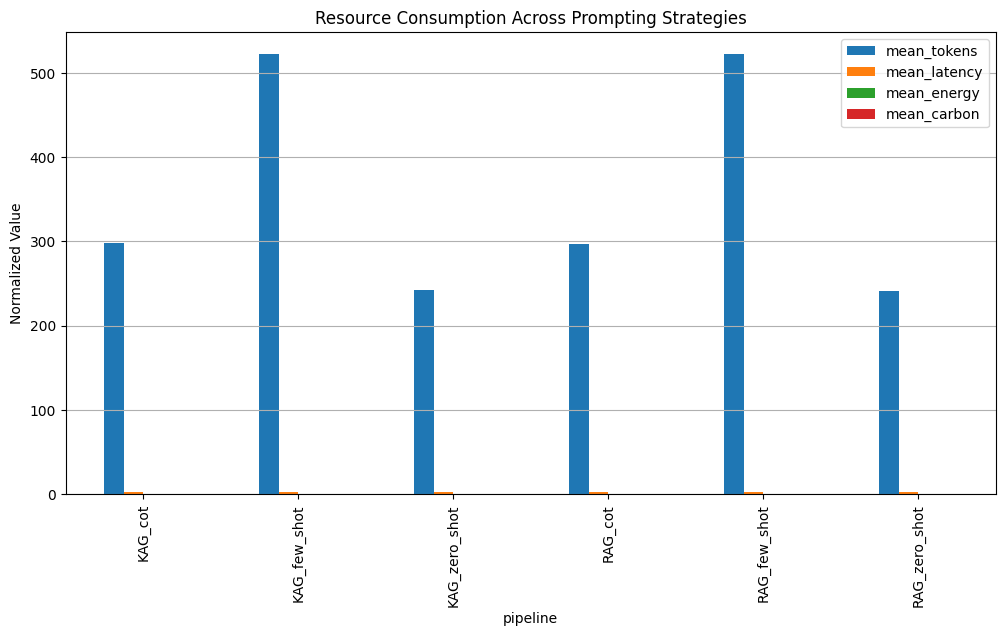


Total Carbon Emissions per Prompting Strategy (kg CO₂e):
        pipeline  total_carbon_kg
0        KAG_cot           0.0170
1   KAG_few_shot           0.0167
2  KAG_zero_shot           0.0175
3        RAG_cot           0.0164
4   RAG_few_shot           0.0155
5  RAG_zero_shot           0.0166


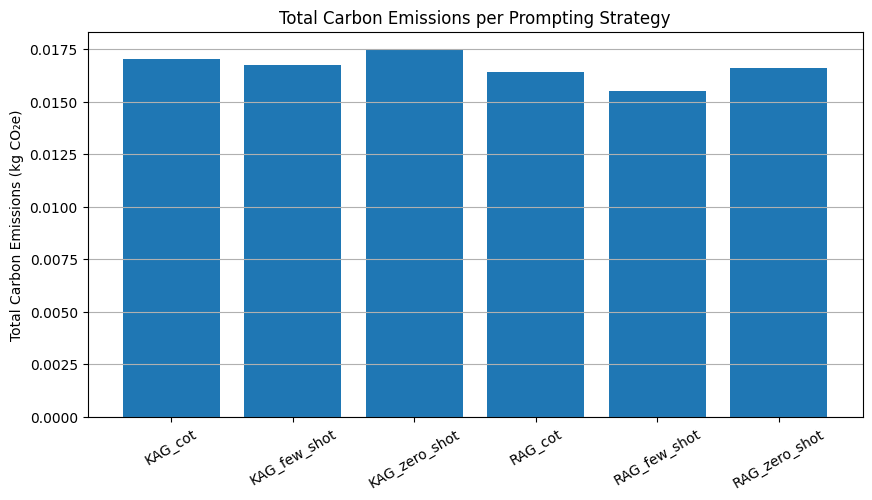


Class-wise Performance Metrics per Pipeline:
         pipeline      class  accuracy  precision  recall  f1_score  support
0   KAG_zero_shot  Duplicate    0.8875     0.2000  0.2667    0.2286       15
1   KAG_zero_shot   Conflict    0.3417     0.3085  0.7654    0.4397       81
2   KAG_zero_shot    Neutral    0.3708     0.3158  0.0417    0.0736      144
3    KAG_few_shot  Duplicate    0.7417     0.1690  0.8000    0.2791       15
4    KAG_few_shot   Conflict    0.5667     0.3763  0.4321    0.4023       81
5    KAG_few_shot    Neutral    0.6500     0.8947  0.4722    0.6182      144
6         KAG_cot  Duplicate    0.7708     0.1429  0.5333    0.2254       15
7         KAG_cot   Conflict    0.6750     0.5429  0.2346    0.3276       81
8         KAG_cot    Neutral    0.7292     0.7651  0.7917    0.7782      144
9   RAG_zero_shot  Duplicate    0.8728     0.2632  0.2500    0.2564       20
10  RAG_zero_shot   Conflict    0.4474     0.4508  0.8131    0.5800      107
11  RAG_zero_shot    Neutral  

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

file_path = ""
df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Total samples:", len(df))


pipelines = [
    "KAG_zero_shot",
    "KAG_few_shot",
    "KAG_cot",
    "RAG_zero_shot",
    "RAG_few_shot",
    "RAG_cot"
]

df = df[df["pipeline"].isin(pipelines)]

metrics = []

for pipe in pipelines:
    subset = df[df["pipeline"] == pipe]

    acc = accuracy_score(subset["ground_truth"], subset["label"])
    prec = precision_score(subset["ground_truth"], subset["label"], average="weighted")
    rec = recall_score(subset["ground_truth"], subset["label"], average="weighted")
    f1 = f1_score(subset["ground_truth"], subset["label"], average="weighted")

    metrics.append({
        "pipeline": pipe,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1_score": f1
    })

metrics_df = pd.DataFrame(metrics)

print("\nPerformance Metrics per Prompting Strategy:")
print(metrics_df.round(4))
metrics_df.set_index("pipeline").plot(kind="bar", figsize=(12, 6))
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Performance Comparison Across Prompting Strategies")
plt.grid(axis="y")
plt.show()

important_features = [
    "confidence",
    "input_tokens",
    "latency_s",
    "energy_kwh",
    "carbon_kg",
    "avg_power_watts"
]



resource_stats = (
    df.groupby("pipeline")
      .agg(
          mean_tokens=("input_tokens", "mean"),
          mean_latency=("latency_s", "mean"),
          mean_energy=("energy_kwh", "mean"),
          mean_carbon=("carbon_kg", "mean"),
          mean_confidence=("confidence", "mean")
      )
      .reset_index()
)

print("\nMean Resource Usage per Prompting Strategy:")
print(resource_stats.round(4))

# Plot resource vs pipeline
resource_stats.set_index("pipeline")[[
    "mean_tokens",
    "mean_latency",
    "mean_energy",
    "mean_carbon"
]].plot(kind="bar", figsize=(12, 6))

plt.title("Resource Consumption Across Prompting Strategies")
plt.ylabel("Normalized Value")
plt.grid(axis="y")
plt.show()

total_carbon = (
    df.groupby("pipeline")["carbon_kg"]
      .sum()
      .reset_index()
      .rename(columns={"carbon_kg": "total_carbon_kg"})
)

print("\nTotal Carbon Emissions per Prompting Strategy (kg CO₂e):")
print(total_carbon.round(4))

plt.figure(figsize=(10, 5))
plt.bar(
    total_carbon["pipeline"],
    total_carbon["total_carbon_kg"]
)
plt.ylabel("Total Carbon Emissions (kg CO₂e)")
plt.title("Total Carbon Emissions per Prompting Strategy")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.show()


class_wise_metrics = []

classes = df["ground_truth"].unique()  

for pipe in pipelines:
    pipe_df = df[df["pipeline"] == pipe]

    for cls in classes:
        y_true = (pipe_df["ground_truth"] == cls).astype(int)
        y_pred = (pipe_df["label"] == cls).astype(int)

        class_wise_metrics.append({
            "pipeline": pipe,
            "class": cls,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1_score": f1_score(y_true, y_pred, zero_division=0),
            "support": (pipe_df["ground_truth"] == cls).sum()
        })

class_wise_df = pd.DataFrame(class_wise_metrics)

print("\nClass-wise Performance Metrics per Pipeline:")
print(class_wise_df.round(4))